# Root cause investigation: service ranking and temporal associations

Fit each service's normal reference from the correct scenarios in the training runs. The per-second score is the median absolute deviation from the training median across variable signals, scaled by each signal's interquartile range or training standard deviation. The training 95th percentile sets the reference for each service.

Rank services within a held-out scenario by the fraction of observed seconds exceeding their references. Break ties with the earliest persistent onset, defined by three consecutive exceedances. Missing seconds interrupt persistence. Correct test scenarios provide a comparison for the same runs.

In [1]:
from pathlib import Path
import json
import subprocess
import sys

import matplotlib.pyplot as plt
import pandas as pd

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
subprocess.run([sys.executable, "-m", "src.root_cause"], cwd=root, check=True)
results = root / "results"
summary = json.loads((results / "rca_summary.json").read_text())
ranks = pd.read_csv(results / "rca_rankings.csv")
assert len(ranks) == summary["service_rankings"]
assert ranks.groupby(["run", "test"]).service.nunique().eq(7).all()
assert set(ranks.run) == set(summary["runs"])
context = ranks.loc[ranks.run.eq(summary["example_run"])]
display(context.loc[context.test.eq(summary["example_scenario"])].round(3))
display(context.loc[context.test.eq("correct")].round(3))

,run,test,service,observations,fraction_above_reference,median_score,onset_seconds,rank
189,LO2_run_1738661358,get_token_404,service,148,0.378,0.698,NaN,1
190,LO2_run_1738661358,get_token_404,key,148,0.277,0.686,NaN,2
191,LO2_run_1738661358,get_token_404,refresh-token,148,0.236,0.685,NaN,3
192,LO2_run_1738661358,get_token_404,user,148,0.169,0.631,NaN,4
193,LO2_run_1738661358,get_token_404,code,148,0.034,0.272,NaN,5
194,LO2_run_1738661358,get_token_404,client,148,0.007,0.270,NaN,6
195,LO2_run_1738661358,get_token_404,token,148,0.000,0.335,NaN,7


,run,test,service,observations,fraction_above_reference,median_score,onset_seconds,rank
126,LO2_run_1738661358,correct,service,128,0.297,0.698,NaN,1
127,LO2_run_1738661358,correct,user,128,0.242,0.675,NaN,2
128,LO2_run_1738661358,correct,refresh-token,128,0.219,0.685,NaN,3
129,LO2_run_1738661358,correct,key,128,0.070,0.601,NaN,4
130,LO2_run_1738661358,correct,code,128,0.016,0.356,NaN,5
131,LO2_run_1738661358,correct,client,128,0.008,0.348,NaN,6
132,LO2_run_1738661358,correct,token,128,0.000,0.406,NaN,7


## Inspect a held-out scenario

The plot divides each service's deviation score by its own threshold. Values above one exceed the training reference. For each service pair, examine Spearman correlation at lags of minus five to plus five seconds, using available timestamp pairs. A positive lag means the second service is observed later than the first. The values are exploratory because adjacent observations are dependent and many lags are inspected.

The source labels identify client API scenarios. The sampled data lack causal-service labels and validated dependency edges. Service ranks and temporal associations generate hypotheses for investigation. Causal localization accuracy and dependency-graph validation require additional evidence.

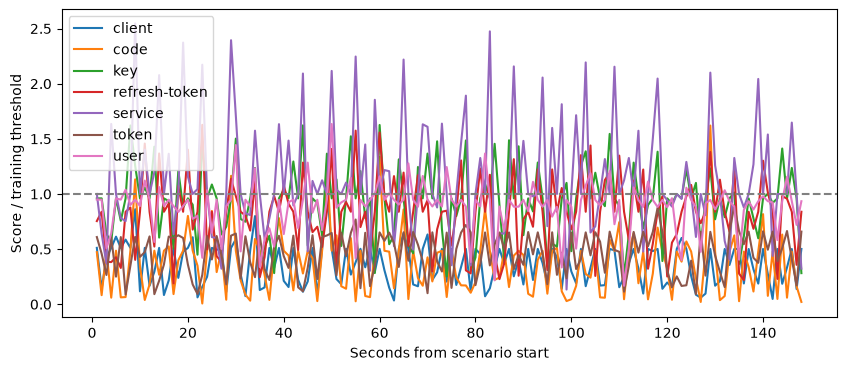

,first_service,second_service,lag_seconds,paired_seconds,spearman
0,refresh-token,service,0,148,0.388
1,client,refresh-token,-2,146,-0.326
2,code,key,0,148,0.292
3,code,refresh-token,-3,145,-0.283
4,refresh-token,user,0,148,0.276
5,key,refresh-token,0,148,0.256
6,code,key,5,143,0.254
7,code,service,5,143,0.253
8,client,key,0,148,0.250
9,code,token,2,146,-0.245


In [2]:
scores = pd.read_csv(results / "rca_example_scores.csv").set_index("elapsed_seconds")
ax = scores.plot(figsize=(10, 4))
ax.axhline(1, linestyle="--", color="gray")
ax.set(xlabel="Seconds from scenario start", ylabel="Score / training threshold")
plt.show()

lags = pd.read_csv(results / "rca_lag_associations.csv")
display(lags.head(10).round(3))